# Task 2 — Gestalt grouping

**Status:** all supplied-data analysis is executed. Human observations are deliberately unfilled. Run the interactive collection cell, use a real reader, then rerun the analysis cells below it. Blank responses are not evidence. No simulated results are used.

Charts use the object-oriented Matplotlib API. Experimental stimuli intentionally retain the supplied colours and omit titles where the brief requires this; they are displays for testing perception, not final explanatory charts.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Circle, Wedge
from IPython.display import display
DATA = Path('data'); RESULTS = Path('results'); FIGURES = Path('figures')
RESULTS.mkdir(exist_ok=True); FIGURES.mkdir(exist_ok=True)
SEED = 42
GREY = '#b9bdc3'; ACCENT = '#bd3f58'
plt.rcParams.update({'figure.dpi': 110, 'axes.titlesize': 12, 'axes.labelsize': 10})
def clean(ax):
    for side in ('top','right'): ax.spines[side].set_visible(False)
def save(fig, name):
    fig.savefig(FIGURES / name, dpi=300, bbox_inches='tight')


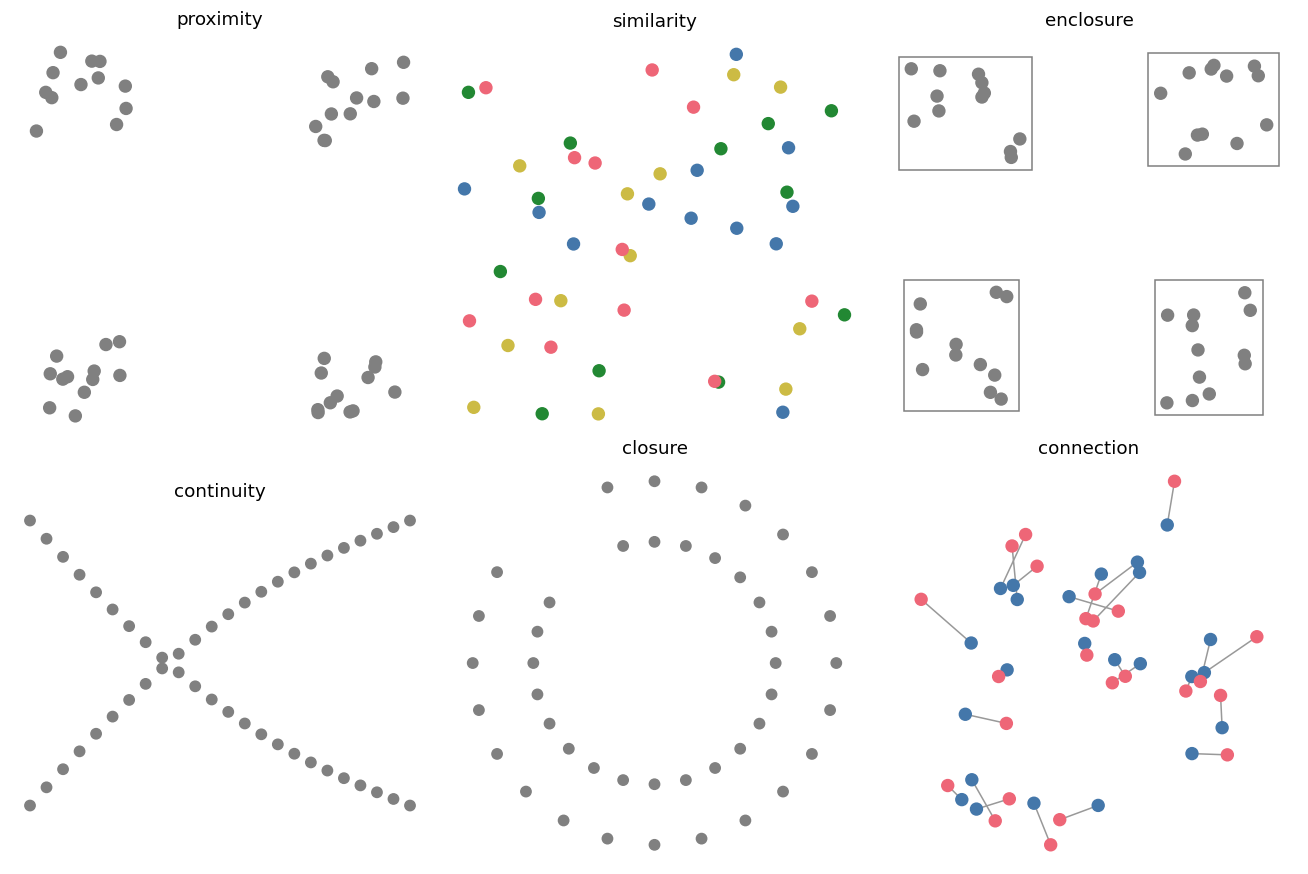

In [2]:
gestalt=pd.read_csv(DATA/'stimuli_gestalt.csv')
principles=['proximity','similarity','enclosure','continuity','closure','connection']
def draw_panel(panel,ax,lines=True):
    d=gestalt[gestalt.panel.eq(panel)]
    if panel=='connection' and lines:
        for _, pair in d.groupby('connector'):
            ax.plot(pair.x,pair.y,color='#999999',lw=1,zorder=0)
    if panel=='enclosure':
        for _,group in d.groupby('group'):
            x0,y0=group.x.min()-.25,group.y.min()-.25
            ax.add_patch(Rectangle((x0,y0),group.x.max()-x0+.25,group.y.max()-y0+.25,fill=False,edgecolor='grey'))
    for (colour,shape),group in d.groupby(['colour','shape']):
        ax.scatter(group.x,group.y,c=colour,s=group['size'],marker={'circle':'o','square':'s'}.get(shape,'o'))
    ax.set_aspect('equal');ax.set_axis_off();ax.set_title(panel)
fig,axes=plt.subplots(2,3,figsize=(12,8))
for panel,ax in zip(principles,axes.flat):draw_panel(panel,ax)
fig.tight_layout();save(fig,'task2_six_principles.png');plt.show()


**What the eye does, panel by panel:** proximity uses spatial clusters of identical dots; similarity uses four nominal hues in an unseparated cloud; enclosure uses grey rectangle boundaries; continuity follows two crossing smooth paths; closure completes the two deliberately broken rings; connection groups endpoints by lines despite different hues and non-nearest partners. Point position is stimulus geometry; colour is categorical, not magnitude. All supplied items remain (closure has 44); multiple colours are necessary experimental manipulations rather than competing final-chart highlights.

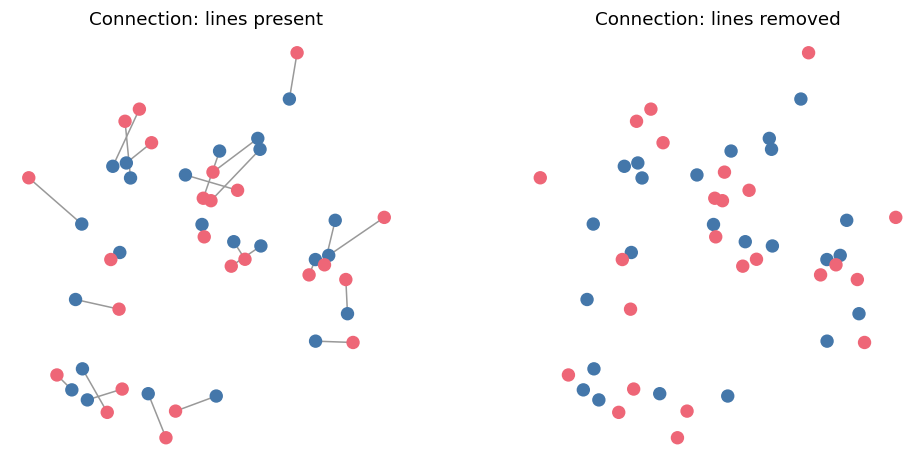

In [3]:
fig,axes=plt.subplots(1,2,figsize=(11,5))
draw_panel('connection',axes[0],True);axes[0].set_title('Connection: lines present')
draw_panel('connection',axes[1],False);axes[1].set_title('Connection: lines removed')
save(fig,'task2_connection_conflict.png');plt.show()


**Conflict:** the added lines encode connection, while hue signals similarity and distance signals proximity. With lines, the intended groups are 24 pairs; without lines there is no uniquely correct perceptual grouping. Ask the reader what rule they used as well as how many groups they saw. Connection winning is an expectation to test, not a result already observed.

In [4]:
import ipywidgets as widgets
path=RESULTS/'gestalt_results.csv'
if not path.exists():
    pd.DataFrame({'panel':principles+['connection_without_lines'],
       'principle':principles+['similarity/proximity'],
       'true_groups':[gestalt[gestalt.panel.eq(p)].group.nunique() for p in principles]+[np.nan],
       'participant':['']*7,'perceived_groups':[np.nan]*7,'reader_explanation':['']*7}).to_csv(path,index=False)
reader=widgets.Text(description='Reader:'); fields=[widgets.IntText(value=0,description=p,style={'description_width':'180px'},layout=widgets.Layout(width='350px')) for p in principles+['without lines']]
notes=[widgets.Text(description='Reason:') for _ in fields];button=widgets.Button(description='Save actual answers');msg=widgets.Output()
def record_gestalt(_):
    with msg:
        msg.clear_output()
        if not reader.value.strip() or any(f.value<1 for f in fields):print('Enter a reader and their positive group counts.');return
        d=pd.read_csv(path);d['participant']=reader.value.strip();d['perceived_groups']=[f.value for f in fields];d['reader_explanation']=[n.value for n in notes]
        d['match']=np.where(d.true_groups.isna(),'not applicable',np.where(d.true_groups.eq(d.perceived_groups),'yes','no'));d.to_csv(path,index=False);display(d)
button.on_click(record_gestalt)
display(widgets.VBox([reader]+[widgets.HBox([f,n]) for f,n in zip(fields,notes)]+[button,msg]))
display(pd.read_csv(path))


,panel,principle,true_groups,participant,perceived_groups,reader_explanation
0,proximity,proximity,4.0,NaN,NaN,NaN
1,similarity,similarity,4.0,NaN,NaN,NaN
2,enclosure,enclosure,4.0,NaN,NaN,NaN
3,continuity,continuity,2.0,NaN,NaN,NaN
4,closure,closure,2.0,NaN,NaN,NaN
5,connection,connection,24.0,NaN,NaN,NaN
6,connection_without_lines,similarity/proximity,NaN,NaN,NaN,NaN


The prompts are “How many groups do you see?” and “What made those items belong together?” Ask without revealing true counts. Results and which principle won remain pending; do not copy the expected count into an observation.

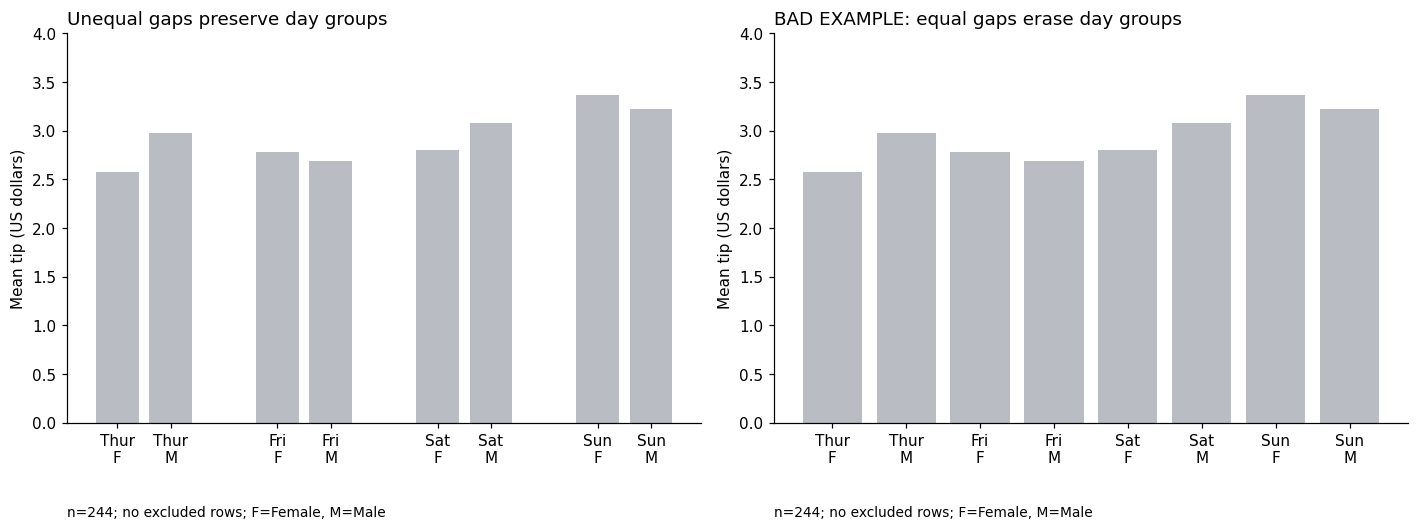

sex,Female,Male
day,,
Thur,2.58,2.98
Fri,2.78,2.69
Sat,2.80,3.08
Sun,3.37,3.22


In [5]:
tips=pd.read_csv(DATA/'tips.csv')
means=tips.groupby(['day','sex'],observed=True).tip.mean().unstack().reindex(['Thur','Fri','Sat','Sun'])
fig,axes=plt.subplots(1,2,figsize=(13,5))
for ax,grouped in zip(axes,[True,False]):
    positions=[];labels=[]
    for i,day in enumerate(means.index):
        for j,sex in enumerate(['Female','Male']):
            x=i*3+j if grouped else i*2+j;positions.append(x);labels.append(f'{day}\n{sex[0]}')
            ax.bar(x,means.loc[day,sex],width=.8,color=GREY)
    ax.set_xticks(positions,labels);ax.set_ylim(0,4);ax.set_ylabel('Mean tip (US dollars)')
    ax.set_title('Unequal gaps preserve day groups' if grouped else 'BAD EXAMPLE: equal gaps erase day groups',loc='left');clean(ax)
    ax.text(0,-.24,'n=244; no excluded rows; F=Female, M=Male',transform=ax.transAxes,fontsize=9)
fig.tight_layout();save(fig,'task2_proximity_tips.png');plt.show();display(means.round(2))


**What the eye does:** bar length on a zero baseline encodes mean dollar tip; common position supports quantitative comparison. Smaller within-day gaps implement proximity. Equal gaps weaken that grouping even though the numbers and labels are unchanged. Grey treats all bars as context; there is no unnecessary pop-out. The equal-gap version is a labelled design failure.

**Six existing chart features:** proximity groups bars within a category; similarity groups repeated symbol types in a legend; enclosure groups a small-multiple panel inside its border; closure lets a partially framed plotting area still read as a rectangle; continuity helps trace a smooth series; connection links observations in a line chart.

**Direct labels:** proximity puts a name beside its mark, reducing the extraneous load of remembering a legend hue, searching for it elsewhere, and matching it. If a leader line is needed, connection makes the association explicit. The useful comprehension effort is preserved.